# Notebook 05 — Feature Engineering

**Purpose:** Create medically/public-health meaningful engineered features. Every new feature is justified and documented.

**Inputs:** Cleaned dataset, train/test indices from Notebook 02

**Outputs:**
- Feature-engineered dataset (`data/processed/df1_engineered.csv`)
- Feature dictionary (`results/tables/05_feature_dictionary.csv`)


In [1]:
import sys, os
sys.path.insert(0, os.path.abspath(".."))

import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
import warnings
warnings.filterwarnings("ignore")

from src.config import *
from src.data_utils import (
    load_dataset1, engineer_features, ENGINEERED_FEATURES,
    FEATURE_DICTIONARY, ALL_ORIGINAL_FEATURES, BINARY_FEATURES,
    ORDINAL_FEATURES, CONTINUOUS_FEATURES, save_artifact,
)
from src.plotting import CLASS_COLOURS, CLASS_NAMES, save_figure

seed_everything()

df = pd.read_csv(os.path.join(DATA_PROCESSED, "df1_cleaned.csv"))
print(f"Input shape: {df.shape}")


Input shape: (253680, 22)


## 5.1 Apply Feature Engineering

In [2]:
# Apply all engineered features
df_eng = engineer_features(df)
new_cols = [c for c in df_eng.columns if c not in df.columns]
print(f"Output shape: {df_eng.shape}")
print(f"New features added: {len(new_cols)}")
for col in new_cols:
    print(f"  - {col}: {FEATURE_DICTIONARY.get(col, 'N/A')}")


Output shape: (253680, 30)
New features added: 8
  - BMI_Category: BMI grouped into clinical categories (Underweight through Obese III)
  - Age_Group: Age collapsed into three life-stage groups (Young / Middle / Senior)
  - Health_Burden: Sum of chronic-condition indicators (HighBP, HighChol, Stroke, HeartDisease, DiffWalk)
  - Healthy_Lifestyle: Net healthy-behaviour score (PhysActivity + Fruits + Veggies − Smoker − HvyAlcohol)
  - Healthcare_Access: Healthcare accessibility indicator (AnyHealthcare − NoDocbcCost)
  - Mental_Physical_Days: Combined poor-health days (MentHlth + PhysHlth)
  - BMI_Age_Interaction: BMI × Age interaction capturing age-dependent obesity effect
  - GenHlth_BMI: General-health rating × BMI capturing perceived-health/obesity relationship


## 5.2 Engineered Feature Descriptions

| Feature | Description | Justification |
|---------|------------|---------------|
| BMI_Category | BMI grouped into clinical categories (Underweight → Obese III) | Clinical BMI categories are standard in public health and capture non-linear BMI effects |
| Age_Group | Three life-stage groups: Young (18-39), Middle (40-64), Senior (65+) | Simplifies 13-level age into clinically relevant stages |
| Health_Burden | Sum of: HighBP + HighChol + Stroke + HeartDisease + DiffWalk | Captures cumulative chronic condition load |
| Healthy_Lifestyle | PhysActivity + Fruits + Veggies − Smoker − HvyAlcohol | Net healthy-behaviour score |
| Healthcare_Access | AnyHealthcare − NoDocbcCost | Access-to-care indicator |
| Mental_Physical_Days | MentHlth + PhysHlth | Combined poor-health burden |
| BMI_Age_Interaction | BMI × Age | Captures age-dependent obesity effects |
| GenHlth_BMI | GenHlth × BMI | Self-perceived health interacted with objective BMI |


## 5.3 Engineered Feature Analysis

Figure saved: d:\DAV\AI_Driven_Public_Health_Surveillance\results/figures\05_engineered_features.png


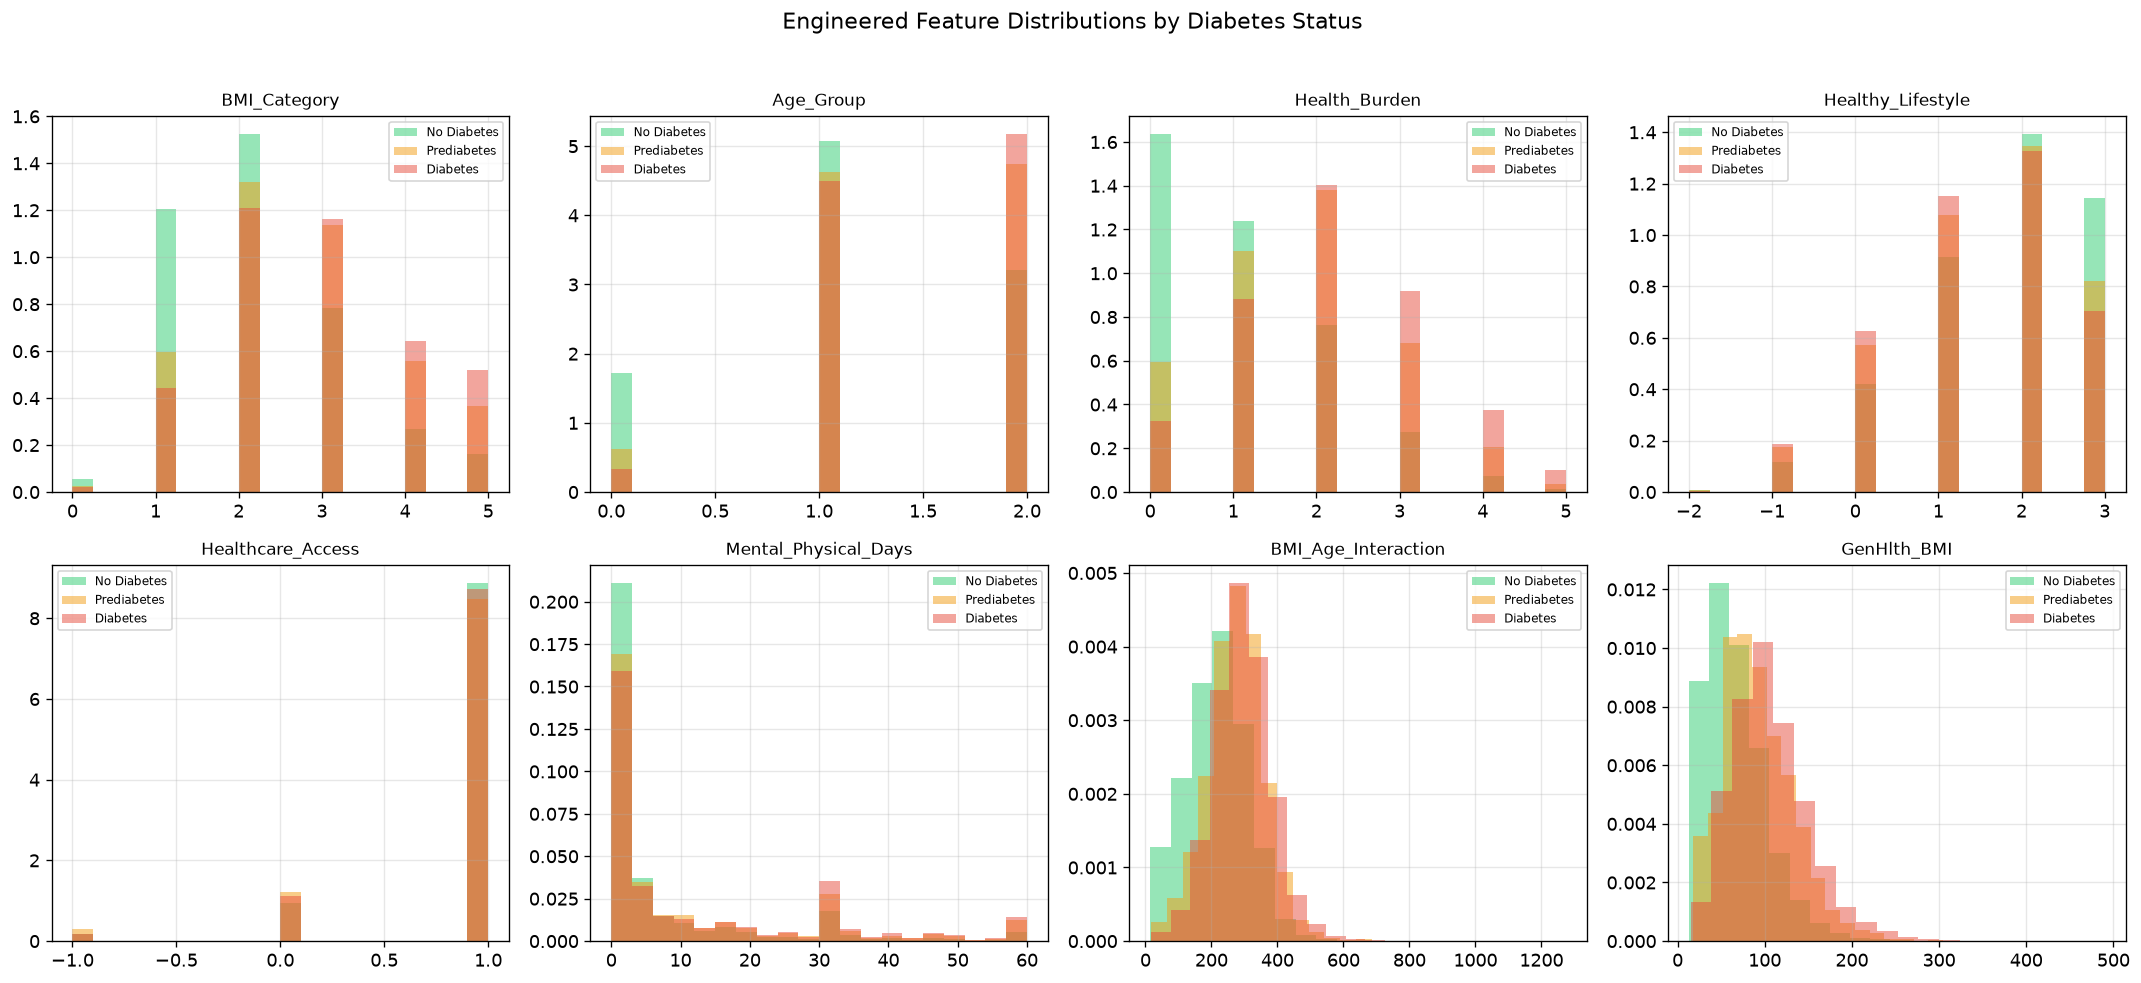

In [3]:
# Analyse each engineered feature by class
fig, axes = plt.subplots(2, 4, figsize=(18, 8))
axes = axes.flatten()

for i, col in enumerate(ENGINEERED_FEATURES):
    for cls in range(N_CLASSES):
        subset = df_eng[df_eng[TARGET_COL] == cls][col]
        axes[i].hist(subset, bins=20, alpha=0.5, label=CLASS_NAMES[cls],
                     color=CLASS_COLOURS[cls], density=True)
    axes[i].set_title(col, fontsize=10)
    axes[i].legend(fontsize=7)

plt.suptitle("Engineered Feature Distributions by Diabetes Status", y=1.02)
plt.tight_layout()
save_figure(fig, os.path.join(RESULTS_FIGURES, "05_engineered_features.png"))
plt.show()


In [4]:
# Correlation of engineered features with target
eng_corrs = []
for col in ENGINEERED_FEATURES:
    from scipy.stats import spearmanr
    rho, pval = spearmanr(df_eng[col], df_eng[TARGET_COL])
    eng_corrs.append({"Feature": col, "Spearman_rho": rho, "abs_rho": abs(rho), "p_value": pval})

eng_corr_df = pd.DataFrame(eng_corrs).sort_values("abs_rho", ascending=False)
print("Engineered feature correlations with target:")
print(eng_corr_df.to_string(index=False))


Engineered feature correlations with target:
             Feature  Spearman_rho  abs_rho      p_value
       Health_Burden      0.333843 0.333843 0.000000e+00
         GenHlth_BMI      0.331756 0.331756 0.000000e+00
 BMI_Age_Interaction      0.294104 0.294104 0.000000e+00
        BMI_Category      0.229069 0.229069 0.000000e+00
           Age_Group      0.174689 0.174689 0.000000e+00
Mental_Physical_Days      0.129957 0.129957 0.000000e+00
   Healthy_Lifestyle     -0.107568 0.107568 0.000000e+00
   Healthcare_Access     -0.021335 0.021335 6.129839e-27


## 5.4 Feature Dictionary

In [5]:
# Create complete feature dictionary
all_features = ALL_ORIGINAL_FEATURES + ENGINEERED_FEATURES
feat_dict_rows = []

# Original features
original_desc = {
    "HighBP": "High blood pressure (0=No, 1=Yes)",
    "HighChol": "High cholesterol (0=No, 1=Yes)",
    "CholCheck": "Cholesterol check in past 5 years (0=No, 1=Yes)",
    "BMI": "Body Mass Index (integer)",
    "Smoker": "Smoked ≥100 cigarettes in lifetime (0=No, 1=Yes)",
    "Stroke": "Ever had a stroke (0=No, 1=Yes)",
    "HeartDiseaseorAttack": "Coronary heart disease or myocardial infarction (0=No, 1=Yes)",
    "PhysActivity": "Physical activity in past 30 days (0=No, 1=Yes)",
    "Fruits": "Consume fruit ≥1 time/day (0=No, 1=Yes)",
    "Veggies": "Consume vegetables ≥1 time/day (0=No, 1=Yes)",
    "HvyAlcoholConsump": "Heavy alcohol consumption (0=No, 1=Yes)",
    "AnyHealthcare": "Has healthcare coverage (0=No, 1=Yes)",
    "NoDocbcCost": "Could not see doctor due to cost in past year (0=No, 1=Yes)",
    "GenHlth": "General health (1=Excellent, 2=Very Good, 3=Good, 4=Fair, 5=Poor)",
    "MentHlth": "Days of poor mental health in past 30 days (0-30)",
    "PhysHlth": "Days of poor physical health in past 30 days (0-30)",
    "DiffWalk": "Serious difficulty walking or climbing stairs (0=No, 1=Yes)",
    "Sex": "Sex (0=Female, 1=Male)",
    "Age": "13-level age category (1=18-24 to 13=80+)",
    "Education": "Education level (1=No school to 6=College graduate)",
    "Income": "Income level (1=<$10K to 8=≥$75K)",
}

for feat in ALL_ORIGINAL_FEATURES:
    feat_dict_rows.append({
        "Feature": feat, "Type": "Original",
        "Description": original_desc.get(feat, ""),
    })
for feat in ENGINEERED_FEATURES:
    feat_dict_rows.append({
        "Feature": feat, "Type": "Engineered",
        "Description": FEATURE_DICTIONARY.get(feat, ""),
    })

feat_dict_df = pd.DataFrame(feat_dict_rows)
feat_dict_df.to_csv(os.path.join(RESULTS_TABLES, "05_feature_dictionary.csv"), index=False)
print(feat_dict_df.to_string(index=False))


             Feature       Type                                                                            Description
              HighBP   Original                                                      High blood pressure (0=No, 1=Yes)
            HighChol   Original                                                         High cholesterol (0=No, 1=Yes)
           CholCheck   Original                                        Cholesterol check in past 5 years (0=No, 1=Yes)
              Smoker   Original                                       Smoked ≥100 cigarettes in lifetime (0=No, 1=Yes)
              Stroke   Original                                                        Ever had a stroke (0=No, 1=Yes)
HeartDiseaseorAttack   Original                          Coronary heart disease or myocardial infarction (0=No, 1=Yes)
        PhysActivity   Original                                        Physical activity in past 30 days (0=No, 1=Yes)
              Fruits   Original                 

## 5.5 Save Outputs

In [6]:
# Save engineered dataset
df_eng.to_csv(os.path.join(DATA_PROCESSED, "df1_engineered.csv"), index=False)
print(f"✓ Engineered dataset saved: {df_eng.shape}")
print(f"  Original features: {len(ALL_ORIGINAL_FEATURES)}")
print(f"  Engineered features: {len(ENGINEERED_FEATURES)}")
print(f"  Total features: {len(ALL_ORIGINAL_FEATURES) + len(ENGINEERED_FEATURES)}")


✓ Engineered dataset saved: (253680, 30)
  Original features: 21
  Engineered features: 8
  Total features: 29


## 5.6 Conclusion

**Feature engineering summary:**

1. Created **8 engineered features** based on medical/public-health domain knowledge.
2. **Health_Burden** and **BMI_Age_Interaction** show strong separation between diabetes classes.
3. **Healthy_Lifestyle** captures the protective effect of positive health behaviours.
4. All engineered features have clear medical justification documented in the feature dictionary.
5. Original features are preserved alongside engineered features.

**Next:** Notebook 06 — Feature Selection
